<a href="https://colab.research.google.com/github/yungweiwang/bert-ag-news-classification/blob/main/bert_ag_news.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install transformers datasets accelerate scikit-learn pandas matplotlib seaborn

In [2]:
import torch
import transformers
import datasets

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
GPU available: True
GPU: Tesla T4


In [3]:
import torch
import torch.nn as nn

embedding = nn.Embedding(
    num_embeddings=5,
    embedding_dim=4
)

tokens = torch.tensor([0, 1, 2])

vectors = embedding(tokens)

print("Embedding shape:", vectors.shape)
print(vectors)

Embedding shape: torch.Size([3, 4])
tensor([[ 1.7649,  1.0563,  0.6033,  0.7789],
        [-0.4443,  1.1289,  1.4723, -0.3000],
        [-1.1376, -1.7959, -1.3973, -0.0264]], grad_fn=<EmbeddingBackward0>)


In [4]:
# 模擬 2 個句子
# 每句 5 個 tokens
# 每個 token 有 768 維

x = torch.randn(2, 5, 768)

rnn = nn.RNN(
    input_size=768,
    hidden_size=128,
    batch_first=True
)

lstm = nn.LSTM(
    input_size=768,
    hidden_size=128,
    batch_first=True
)

rnn_output, rnn_hidden = rnn(x)
lstm_output, (lstm_hidden, cell) = lstm(x)

print("RNN:", rnn_output.shape)
print("LSTM:", lstm_output.shape)
print("LSTM hidden:", lstm_hidden.shape)
print("LSTM cell:", cell.shape)

RNN: torch.Size([2, 5, 128])
LSTM: torch.Size([2, 5, 128])
LSTM hidden: torch.Size([1, 2, 128])
LSTM cell: torch.Size([1, 2, 128])


In [5]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

sentence = "Apple announces a new AI-powered chip."

tokens = tokenizer.tokenize(sentence)
encoded = tokenizer(sentence)

print("Tokens:", tokens)
print("Token IDs:", encoded["input_ids"])
print("Special tokens:", tokenizer.all_special_tokens)

Tokens: ['apple', 'announces', 'a', 'new', 'ai', '-', 'powered', 'chip', '.']
Token IDs: [101, 6207, 17472, 1037, 2047, 9932, 1011, 6113, 9090, 1012, 102]
Special tokens: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']


In [6]:
%pip install -U datasets huggingface_hub

In [7]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/ag_news")

print(dataset)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [8]:
print(dataset["train"][0])

{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [9]:
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())
print(train_df["label"].value_counts())

Train shape: (120000, 2)
Test shape: (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


label
2    30000
3    30000
1    30000
0    30000
Name: count, dtype: int64


In [10]:
SEED = 42

split = dataset["train"].train_test_split(
    train_size=8000,
    test_size=1000,
    stratify_by_column="label",
    seed=SEED
)

train_data = split["train"]
val_data = split["test"]

test_data = dataset["test"].shuffle(
    seed=SEED
).select(range(1000))

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Train: 8000
Validation: 1000
Test: 1000


In [11]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

train_tokenized = train_data.map(
    tokenize_function,
    batched=True
)

val_tokenized = val_data.map(
    tokenize_function,
    batched=True
)

test_tokenized = test_data.map(
    tokenize_function,
    batched=True
)

print(train_tokenized[0]["input_ids"][:20])

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

[101, 8840, 16564, 5222, 2827, 2330, 2005, 2117, 2095, 2770, 6984, 3410, 2848, 8840, 16564, 5338, 2188, 2007, 2274, 2397]


In [12]:
from transformers import AutoModelForSequenceClassification

id2label = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

label2id = {
    value: key for key, value in id2label.items()
}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!


In [13]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [15]:
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

training_args = TrainingArguments(
    output_dir="./bert-ag-news-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    fp16=True,
    logging_steps=100,
    save_total_limit=1,
    report_to="none",
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer ready!")

Trainer ready!


In [16]:
train_result = trainer.train()

print("Training completed!")
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.314371,0.251332,0.923000,0.923641,0.923000,0.923113
2,0.196274,0.219954,0.931000,0.931338,0.931000,0.930855


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed!
{'train_runtime': 186.8777, 'train_samples_per_second': 85.617, 'train_steps_per_second': 5.351, 'total_flos': 763233099113472.0, 'train_loss': 0.30427409744262696, 'epoch': 2.0}


In [17]:
test_results = trainer.evaluate(
    eval_dataset=test_tokenized
)

print("Test Accuracy:", test_results["eval_accuracy"])
print("Test Precision:", test_results["eval_precision"])
print("Test Recall:", test_results["eval_recall"])
print("Test Macro F1:", test_results["eval_f1"])
print("Test Loss:", test_results["eval_loss"])

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.196274,0.282373,2,0.914000,0.914671,0.914847,0.913836


Test Accuracy: 0.914
Test Precision: 0.9146714542561464
Test Recall: 0.9148468328652714
Test Macro F1: 0.9138355074030284
Test Loss: 0.28237250447273254


In [18]:
from sklearn.metrics import classification_report

predictions = trainer.predict(test_tokenized)

y_true = predictions.label_ids
y_pred = np.argmax(
    predictions.predictions,
    axis=-1
)

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            "World",
            "Sports",
            "Business",
            "Sci/Tech"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       World     0.9627    0.8722    0.9152       266
      Sports     0.9608    0.9959    0.9780       246
    Business     0.8852    0.8780    0.8816       246
    Sci/Tech     0.8500    0.9132    0.8805       242

    accuracy                         0.9140      1000
   macro avg     0.9147    0.9148    0.9138      1000
weighted avg     0.9159    0.9140    0.9140      1000



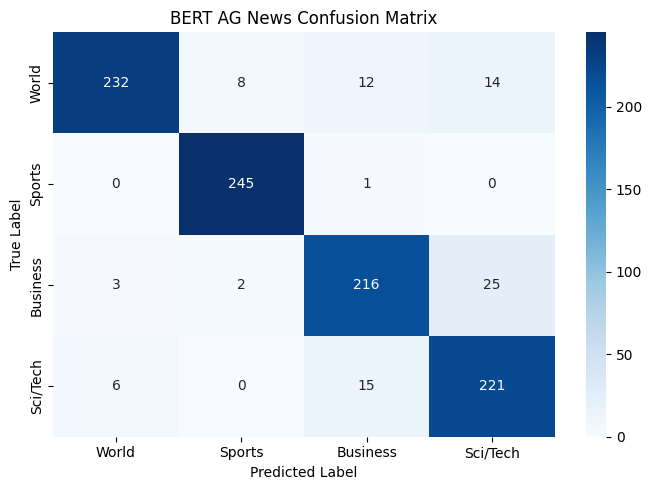

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(id2label.values()),
    yticklabels=list(id2label.values())
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("BERT AG News Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
import os

model_path = "./bert-ag-news-model"

trainer.save_model(model_path)
tokenizer.save_pretrained(model_path)

print("Model saved to:", model_path)
print(os.listdir(model_path))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: ./bert-ag-news-model
['tokenizer.json', 'model.safetensors', 'tokenizer_config.json', 'training_args.bin', 'config.json']


In [21]:
import torch

def predict_news(text):
    model.eval()

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(model.device)

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(
        outputs.logits,
        dim=-1
    )[0]

    predicted_class = torch.argmax(
        probabilities
    ).item()

    return {
        "category": id2label[predicted_class],
        "confidence": round(
            probabilities[predicted_class].item(),
            4
        )
    }

news = "NASA announces a new mission to explore Mars."

print(predict_news(news))

{'category': 'Sci/Tech', 'confidence': 0.9749}


In [22]:
requirements = """torch
transformers>=5.22.1,<6
datasets
accelerate
scikit-learn
pandas
numpy
matplotlib
seaborn
safetensors
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

In [23]:
predict_code = '''
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_PATH = "./bert-ag-news-model"

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model.to(device)
model.eval()

def predict_news(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        logits = model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0]

    predicted_id = probabilities.argmax().item()

    return {
        "category": model.config.id2label[predicted_id],
        "confidence": round(
            probabilities[predicted_id].item(), 4
        )
    }

if __name__ == "__main__":
    text = input("Enter a news article: ")
    print(predict_news(text))
'''

with open("predict.py", "w") as f:
    f.write(predict_code)

In [24]:
import os
import shutil

project = "bert-ag-news-classification"

os.makedirs(f"{project}/results", exist_ok=True)

files = [
    "requirements.txt",
    "predict.py"
]

for file in files:
    shutil.copy(file, project)

shutil.copy(
    "confusion_matrix.png",
    f"{project}/results/confusion_matrix.png"
)

with open(f"{project}/.gitignore", "w") as f:
    f.write(
        "bert-ag-news-model/\n"
        "bert-ag-news-results/\n"
        "__pycache__/\n"
        ".ipynb_checkpoints/\n"
        ".env\n"
    )

print("Project folder created!")

Project folder created!


In [25]:
readme = """# BERT Multi-Class News Classification

Fine-tuning BERT for news classification using PyTorch and Hugging Face.

## Dataset
AG News: World, Sports, Business, Sci/Tech.

## Model
- bert-base-uncased
- Training samples: 8,000
- Validation samples: 1,000
- Test samples: 1,000
- Epochs: 2
- GPU: NVIDIA Tesla T4

## Results
- Validation Accuracy: 93.1%
- Test Accuracy: 91.4%
- Training Time: 187 seconds

## Confusion Matrix
![Confusion Matrix](results/confusion_matrix.png)

## Example Prediction
Input: NASA announces a new mission to explore Mars.

Prediction: Sci/Tech

Softmax confidence: 97.49%

## Technologies
Python, PyTorch, Transformers, Hugging Face,
scikit-learn, pandas, Matplotlib, Google Colab.

## Usage
Install dependencies:

    pip install -r requirements.txt

Place the fine-tuned model files in bert-ag-news-model/,
then run:

    python predict.py
"""

with open(
    "bert-ag-news-classification/README.md",
    "w"
) as f:
    f.write(readme)

print("README created!")

README created!


In [26]:
import shutil
from google.colab import files

shutil.make_archive(
    "bert-ag-news-classification",
    "zip",
    "bert-ag-news-classification"
)

files.download("bert-ag-news-classification.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>